<a href="https://colab.research.google.com/github/Albert-soh1116/data-science-toolkit/blob/main/tutorial04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial 04
Tidy data & asking questions from data (pandas)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## Question 1: Identify the Problem

In [2]:
df1 = pd.DataFrame({
    "Student": ["Ali", "Sara", "John"],
    "Math": [75, 88, 65],
    "Science": [80, 91, 70],
    "English": [72, 85, 68],
})
print("原始数据 (宽格式):")
print(df1)

# 1. Is this data in tidy format?
#    -> No.
# 2. Violated rule:
#    "Each variable must form a column."
#    Math / Science / English 其实是同一个变量 "Subject" 的取值,
#    分数 (Score) 也被分散在三列里,而不是放在一列中。
#    (违反: 每个变量一列 / 列名含有变量的值)

# 3. Reshape with melt
tidy1 = df1.melt(id_vars="Student", var_name="Subject", value_name="Score")
print("\nTidy 格式:")
print(tidy1)

原始数据 (宽格式):
  Student  Math  Science  English
0     Ali    75       80       72
1    Sara    88       91       85
2    John    65       70       68

Tidy 格式:
  Student  Subject  Score
0     Ali     Math     75
1    Sara     Math     88
2    John     Math     65
3     Ali  Science     80
4    Sara  Science     91
5    John  Science     70
6     Ali  English     72
7    Sara  English     85
8    John  English     68


## Question 2: Sales Data

In [3]:
df2 = pd.DataFrame({
    "Country": ["Malaysia", "Thailand", "Indonesia"],
    "Q1_Sales": [12000, 10000, 14000],
    "Q2_Sales": [15000, 11000, 12500],
    "Q3_Sales": [14000, 13000, 15000],
    "Q4_Sales": [18000, 16000, 17000],
})
print("原始数据 (宽格式):")
print(df2)

# 1. Tidy-data problem:
#    Q1_Sales ~ Q4_Sales 这些列名其实是 "Quarter" 这个变量的取值,
#    销售额 (Sales) 被分散在 4 列中 -> 一个变量分布在多列。

# 2. Convert to tidy
tidy2 = df2.melt(id_vars="Country", var_name="Quarter", value_name="Sales")
tidy2["Quarter"] = tidy2["Quarter"].str.replace("_Sales", "", regex=False)
tidy2 = tidy2.sort_values(["Country", "Quarter"], key=lambda s: s.map(
    {"Malaysia": 0, "Thailand": 1, "Indonesia": 2}) if s.name == "Country" else s
).reset_index(drop=True)
print("\nTidy 格式:")
print(tidy2)

原始数据 (宽格式):
     Country  Q1_Sales  Q2_Sales  Q3_Sales  Q4_Sales
0   Malaysia     12000     15000     14000     18000
1   Thailand     10000     11000     13000     16000
2  Indonesia     14000     12500     15000     17000

Tidy 格式:
      Country Quarter  Sales
0    Malaysia      Q1  12000
1    Malaysia      Q2  15000
2    Malaysia      Q3  14000
3    Malaysia      Q4  18000
4    Thailand      Q1  10000
5    Thailand      Q2  11000
6    Thailand      Q3  13000
7    Thailand      Q4  16000
8   Indonesia      Q1  14000
9   Indonesia      Q2  12500
10  Indonesia      Q3  15000
11  Indonesia      Q4  17000


## Question 3: Asking Questions from Data

1. Average study time: 4.833333333333333
2. Average score: 71.67
3. Highest score: F -> 90
4. Studied the most: F -> 8 hours
5. Correlation (Study_Hours vs Score): 0.998
   -> Yes, 学习时间越长,分数越高 (strong positive relationship).


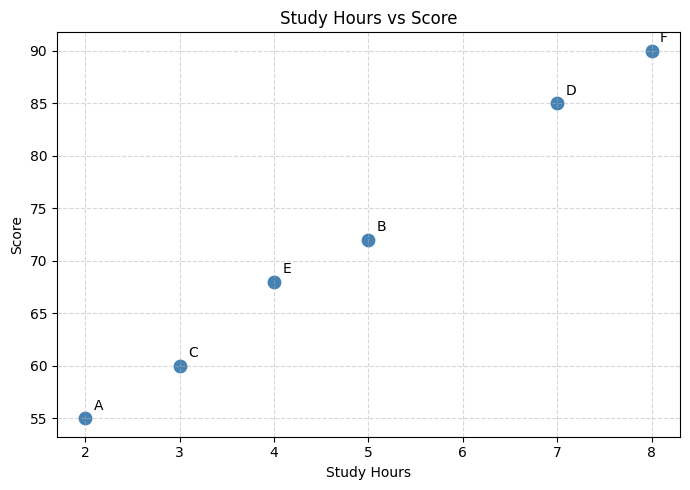

In [4]:
data = {
    "Student": ["A", "B", "C", "D", "E", "F"],
    "Study_Hours": [2, 5, 3, 7, 4, 8],
    "Score": [55, 72, 60, 85, 68, 90],
}
df3 = pd.DataFrame(data)

# 1. Average study time
print("1. Average study time:", df3["Study_Hours"].mean())

# 2. Average score
print("2. Average score:", round(df3["Score"].mean(), 2))

# 3. Student with highest score
best = df3.loc[df3["Score"].idxmax()]
print("3. Highest score:", best["Student"], "->", best["Score"])

# 4. Student who studied the most
most = df3.loc[df3["Study_Hours"].idxmax()]
print("4. Studied the most:", most["Student"], "->", most["Study_Hours"], "hours")

# 5. Does studying more appear to be associated with higher score?
corr = df3["Study_Hours"].corr(df3["Score"])
print("5. Correlation (Study_Hours vs Score):", round(corr, 3))
if corr > 0.7:
    print("   -> Yes, 学习时间越长,分数越高 (strong positive relationship).")

# 6. Scatter plot
plt.figure(figsize=(7, 5))
plt.scatter(df3["Study_Hours"], df3["Score"], color="steelblue", s=80)
for _, row in df3.iterrows():
    plt.annotate(row["Student"], (row["Study_Hours"], row["Score"]),
                 textcoords="offset points", xytext=(6, 6))
plt.title("Study Hours vs Score")
plt.xlabel("Study Hours")
plt.ylabel("Score")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("scatter_plot.png", dpi=150)
plt.show()